# 01. Khám phá dữ liệu House Prices

## 1. Đọc dữ liệu và kiểm tra tổng quan

Mục tiêu: đọc dữ liệu gốc, kiểm tra kích thước, sự khác nhau giữa các cột và kiểu dữ liệu. Chưa thay đổi hoặc điền dữ liệu thiếu.


In [ ]:
from pathlib import Path
import pandas as pd

# Hỗ trợ chạy từ thư mục notebooks hoặc thư mục gốc dự án.
PROJECT_DIR = Path.cwd().parent
if not (PROJECT_DIR / "data" / "raw").is_dir():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Không tìm thấy data/raw. Hãy mở notebook từ thư mục dự án hoặc notebooks."
    )

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Cột chỉ có trong train:", set(train.columns) - set(test.columns))
print("Cột chỉ có trong test:", set(test.columns) - set(train.columns))

display(train.head())
train.info()


Train: (1460, 81)
Test: (1459, 80)
Cột chỉ có trong train: {'SalePrice'}
Cột chỉ có trong test: set()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

### Nhận xét

- Train có 1.460 dòng và 81 cột; test có 1.459 dòng và 80 cột. Hai tập có cùng các cột đầu vào, chỉ train có biến mục tiêu `SalePrice`.
- Train gồm 35 cột int64, 3 cột float64 và 43 cột object. Kiểu dữ liệu lưu trữ chưa phản ánh hoàn toàn ý nghĩa biến; chẳng hạn `MSSubClass` là mã phân loại.


## 2. Kiểm tra giá trị thiếu

Mục tiêu: thống kê số lượng và tỷ lệ NaN trong train/test trước khi quyết định xử lý. NaN có thể xuất phát từ mã biểu thị không có tiện ích hoặc giá trị bị thiếu; cần đối chiếu data_description.txt. Pandas cũng có thể chuyển chuỗi `None` thành NaN, cần lưu ý khi kiểm tra MasVnrType.


In [2]:
# Thống kê NaN theo từng tập, giữ nguyên dữ liệu gốc.
missing_summary = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_missing_pct": train.isna().mean() * 100,
    "test_missing": test.isna().sum(),
    "test_missing_pct": test.isna().mean() * 100,
})

# SalePrice không thuộc schema của test, không phải giá trị thiếu.
missing_summary = missing_summary.drop(index="SalePrice")
missing_summary = missing_summary.loc[
    (missing_summary["train_missing"] > 0)
    | (missing_summary["test_missing"] > 0)
].sort_values("train_missing_pct", ascending=False)

display(missing_summary.round(2))
print("Số cột có NaN trong train:", (train.isna().sum() > 0).sum())
print("Số cột có NaN trong test:", (test.isna().sum() > 0).sum())
print("Số SalePrice bị thiếu:", train["SalePrice"].isna().sum())


,train_missing,train_missing_pct,test_missing,test_missing_pct
PoolQC,1453,99.52,1456.0,99.79
MiscFeature,1406,96.30,1408.0,96.50
Alley,1369,93.77,1352.0,92.67
Fence,1179,80.75,1169.0,80.12
MasVnrType,872,59.73,894.0,61.27
FireplaceQu,690,47.26,730.0,50.03
LotFrontage,259,17.74,227.0,15.56
GarageYrBlt,81,5.55,78.0,5.35
GarageQual,81,5.55,78.0,5.35
GarageFinish,81,5.55,78.0,5.35


Số cột có NaN trong train: 19
Số cột có NaN trong test: 33
Số SalePrice bị thiếu: 0


### Nhận xét

- Train có 19 cột chứa NaN, test có 33 cột; `SalePrice` không thiếu giá trị.
- Các cột có tỷ lệ NaN cao ở cả hai tập gồm `PoolQC` (99,52% / 99,79%), `MiscFeature` (96,30% / 96,50%), `Alley` (93,77% / 92,67%) và `Fence` (80,75% / 80,12%), lần lượt theo train/test.
- Một số cột chỉ xuất hiện NaN trong test, như `MSZoning`, `KitchenQual` và `GarageCars`; tiền xử lý cần hỗ trợ cả những trường hợp này.
- Chưa xóa cột hoặc điền thiếu theo tỷ lệ: cần đối chiếu mô tả để phân biệt không có tiện ích với thiếu thông tin. Riêng `MasVnrType`, cần kiểm tra chuỗi `None` có bị pandas chuyển thành NaN hay không.


## 3. Kiểm chứng ý nghĩa các giá trị NaN


In [3]:
# Đọc lại dưới dạng chuỗi và giữ nguyên các mã NA/None để kiểm chứng.
raw_train = pd.read_csv(DATA_DIR / "train.csv", keep_default_na=False, dtype=str)
raw_test = pd.read_csv(DATA_DIR / "test.csv", keep_default_na=False, dtype=str)

columns_to_check = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "MasVnrType", "LotFrontage", "GarageType", "BsmtQual",
]

rows = []
for name, raw, parsed in [("train", raw_train, train), ("test", raw_test, test)]:
    for column in columns_to_check:
        rows.append({
            "dataset": name,
            "column": column,
            "literal_NA": raw[column].eq("NA").sum(),
            "literal_None": raw[column].eq("None").sum(),
            "empty_string": raw[column].eq("").sum(),
            "parsed_NaN": parsed[column].isna().sum(),
        })

display(pd.DataFrame(rows))

# Hiển thị định nghĩa tương ứng để diễn giải các mã trong file gốc.
import re

description = (DATA_DIR / "data_description.txt").read_text()
sections = re.split(r"\n(?=[A-Za-z0-9]+:)", description)
for section in sections:
    if section.split(":", 1)[0].strip() in columns_to_check:
        print(section.strip())
        print()


,dataset,column,literal_NA,literal_None,empty_string,parsed_NaN
0,train,PoolQC,1453,0,0,1453
1,train,MiscFeature,1406,0,0,1406
2,train,Alley,1369,0,0,1369
3,train,Fence,1179,0,0,1179
4,train,FireplaceQu,690,0,0,690
5,train,MasVnrType,8,864,0,872
6,train,LotFrontage,259,0,0,259
7,train,GarageType,81,0,0,81
8,train,BsmtQual,37,0,0,37
9,test,PoolQC,1456,0,0,1456


LotFrontage: Linear feet of street connected to property

Alley: Type of alley access to property

       Grvl	Gravel
       Pave	Paved
       NA 	No alley access

MasVnrType: Masonry veneer type

       BrkCmn	Brick Common
       BrkFace	Brick Face
       CBlock	Cinder Block
       None	None
       Stone	Stone

BsmtQual: Evaluates the height of the basement

       Ex	Excellent (100+ inches)	
       Gd	Good (90-99 inches)
       TA	Typical (80-89 inches)
       Fa	Fair (70-79 inches)
       Po	Poor (<70 inches
       NA	No Basement

FireplaceQu: Fireplace quality

       Ex	Excellent - Exceptional Masonry Fireplace
       Gd	Good - Masonry Fireplace in main level
       TA	Average - Prefabricated Fireplace in main living area or Masonry Fireplace in basement
       Fa	Fair - Prefabricated Fireplace in basement
       Po	Poor - Ben Franklin Stove
       NA	No Fireplace

GarageType: Garage location
		
       2Types	More than one type of garage
       Attchd	Attached to home
       Basme

### Nhận xét

- Theo bảng kiểm chứng và data_description.txt ở trên, mã `NA` trong các cột tiện ích đã kiểm tra (PoolQC, MiscFeature, Alley, Fence, FireplaceQu, GarageType, BsmtQual) biểu thị không có tiện ích tương ứng; không thể coi toàn bộ là thông tin chưa biết chỉ vì pandas hiển thị NaN.
- `MasVnrType` trong train có 864 chuỗi `None` và 8 chuỗi `NA`, nhưng pandas gộp thành 872 NaN. Test có 878 chuỗi `None` và 16 chuỗi `NA`, gộp thành 894 NaN. Theo mô tả, `None` là không có lớp ốp; cần giữ riêng với thông tin chưa biết mang mã `NA`.
- `LotFrontage` có 259 mã `NA` trong train và 227 trong test; mô tả không định nghĩa NA là không có mặt tiền, nên chưa gán các giá trị này bằng 0.
- Các cột được kiểm tra không có chuỗi rỗng. Kết quả cho thấy cần đọc dữ liệu có kiểm soát các mã thiếu khi xây dựng preprocessing; hiện giữ nguyên train/test để bảo toàn kết quả EDA đã chạy.


## 4. Kiểm tra trùng lặp và mã định danh


In [4]:
# Kiểm tra trùng lặp, tính duy nhất và giao nhau của mã nhà.
features = test.columns.drop("Id").tolist()
quality_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "missing_Id": [train["Id"].isna().sum(), test["Id"].isna().sum()],
    "duplicate_Id": [train["Id"].duplicated().sum(), test["Id"].duplicated().sum()],
    "duplicate_full_row": [train.duplicated().sum(), test.duplicated().sum()],
    "duplicate_features": [
        train.duplicated(subset=features).sum(),
        test.duplicated(subset=features).sum(),
    ],
}, index=["train", "test"])
display(quality_summary)

shared_ids = set(train["Id"]) & set(test["Id"])
print("Số Id xuất hiện trong cả train và test:", len(shared_ids))

# Những nhà có cùng đặc trưng chưa chắc là dòng lỗi; chỉ hiển thị để xem xét.
for name, df in [("train", train), ("test", test)]:
    duplicates = df.duplicated(subset=features, keep=False)
    if duplicates.any():
        print(f"Các dòng trùng toàn bộ đặc trưng trong {name}:")
        display(df.loc[duplicates].sort_values(features, na_position="last"))


,rows,missing_Id,duplicate_Id,duplicate_full_row,duplicate_features
train,1460,0,0,0,0
test,1459,0,0,0,0


Số Id xuất hiện trong cả train và test: 0


### Nhận xét

- Theo bảng `quality_summary`, cả train (1.460 dòng) và test (1.459 dòng) đều không có Id thiếu, Id trùng, dòng trùng toàn bộ hoặc dòng trùng toàn bộ đặc trưng khi bỏ Id và SalePrice.
- Theo phép giao hai tập Id, không có Id xuất hiện đồng thời trong train và test. Chưa phát hiện vấn đề trùng lặp theo các phép kiểm tra này; không cần xóa dòng ở bước này.


## 5. Khám phá phân phối giá nhà SalePrice


Số giá trị thiếu: 0
Số giá trị <= 0: 0


,SalePrice
count,1460.0
mean,180921.2
std,79442.5
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


,SalePrice,log1p(SalePrice)
mean,180921.196,12.024
median,163000.000,12.002
skewness,1.883,0.121


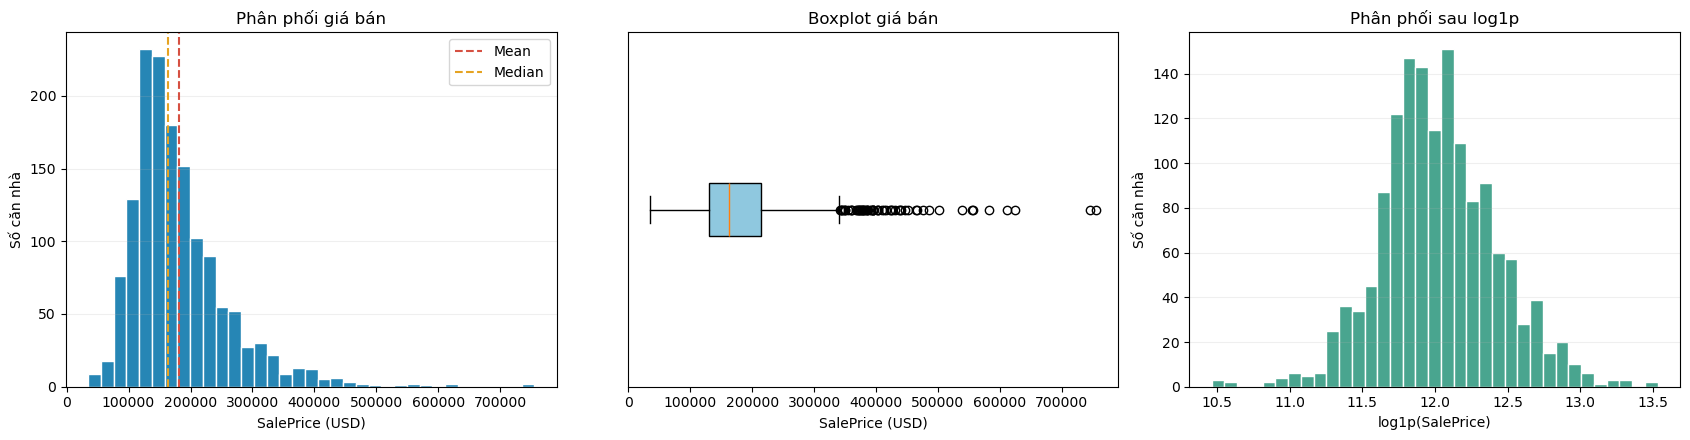

Ngưỡng boxplot theo 1.5 IQR: [3,937.50, 340,037.50]
Số giá nằm ngoài ngưỡng: 61


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Chỉ khám phá trên train; giữ nguyên cột SalePrice gốc.
price = train["SalePrice"]
print("Số giá trị thiếu:", price.isna().sum())
print("Số giá trị <= 0:", price.le(0).sum())
display(price.describe().to_frame("SalePrice").round(2))

if price.dropna().le(0).any():
    raise ValueError("Có giá không dương; cần kiểm tra trước khi xem phân phối log.")

log_price = np.log1p(price)
display(pd.DataFrame({
    "SalePrice": {"mean": price.mean(), "median": price.median(), "skewness": price.skew()},
    "log1p(SalePrice)": {
        "mean": log_price.mean(), "median": log_price.median(), "skewness": log_price.skew()
    },
}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(price.dropna(), bins=35, color="#2686b5", edgecolor="white")
axes[0].axvline(price.mean(), color="#d65042", linestyle="--", label="Mean")
axes[0].axvline(price.median(), color="#e5a322", linestyle="--", label="Median")
axes[0].set(title="Phân phối giá bán", xlabel="SalePrice (USD)", ylabel="Số căn nhà")
axes[0].legend()

axes[1].boxplot(price.dropna(), vert=False, patch_artist=True,
                boxprops={"facecolor": "#8fc8df"})
axes[1].set(title="Boxplot giá bán", xlabel="SalePrice (USD)", yticks=[])

axes[2].hist(log_price.dropna(), bins=35, color="#49a58f", edgecolor="white")
axes[2].set(title="Phân phối sau log1p", xlabel="log1p(SalePrice)", ylabel="Số căn nhà")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

# Các điểm ngoài râu boxplot chỉ được đánh dấu để xem xét, chưa xóa.
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Ngưỡng boxplot theo 1.5 IQR: [{lower:,.2f}, {upper:,.2f}]")
print("Số giá nằm ngoài ngưỡng:", ((price < lower) | (price > upper)).sum())


### Nhận xét

- Theo describe(), SalePrice có đủ 1.460 giá trị, không thiếu và không có giá không dương; giá dao động từ 34.900 đến 755.000 USD.
- Histogram và bảng thống kê cho thấy phân phối lệch phải: trung bình khoảng 180.921 USD lớn hơn trung vị 163.000 USD, skewness là 1,883.
- Sau log1p, skewness giảm còn 0,121 và histogram cân đối hơn. Đây là căn cứ để thử biến đổi mục tiêu khi huấn luyện, chưa khẳng định cải thiện dự đoán nếu chưa đánh giá bằng cross-validation.
- Theo ngưỡng 1,5 IQR [3.937,50; 340.037,50], có 61/1.460 căn nhà (khoảng 4,18%) nằm ngoài râu boxplot. Đây là các giá cực trị cần xem xét, chưa phải lỗi dữ liệu để tự động xóa.


## 6. Mối liên hệ giữa đặc trưng số và giá nhà


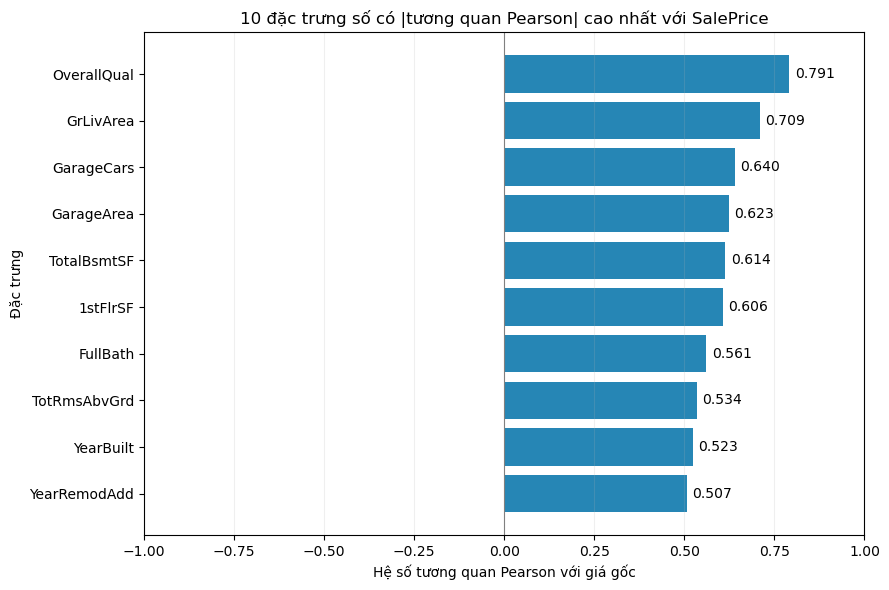

In [6]:
# Pearson chỉ mô tả quan hệ tuyến tính trên các cặp giá trị không thiếu.
# Loại Id và các mã phân loại/thời điểm khỏi biểu đồ tương quan số này.
exclude = ["Id", "MSSubClass", "MoSold", "YrSold", "SalePrice"]
numeric_features = train.select_dtypes(include="number").drop(
    columns=exclude, errors="ignore"
)
correlations = numeric_features.corrwith(train["SalePrice"])
top_correlations = correlations.dropna().loc[
    correlations.dropna().abs().sort_values(ascending=False).head(10).index
].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#2686b5" if value >= 0 else "#d65042" for value in top_correlations]
bars = ax.barh(top_correlations.index, top_correlations.values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set(
    title="10 đặc trưng số có |tương quan Pearson| cao nhất với SalePrice",
    xlabel="Hệ số tương quan Pearson với giá gốc",
    ylabel="Đặc trưng",
)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


### Nhận xét biểu đồ tương quan ở mục 6

Cả 10 đặc trưng số trên biểu đồ đều có tương quan Pearson dương với giá bán `SalePrice`. Điều này cho thấy giá nhà có xu hướng tăng khi các đặc trưng này tăng.

- `OverallQual` (chất lượng tổng thể) có tương quan cao nhất với giá bán, đạt 0,791.
- `GrLivArea` (diện tích sinh hoạt trên mặt đất) đứng thứ hai, đạt 0,709.
- `GarageCars` (sức chứa ô tô của gara) đứng thứ ba, đạt 0,640.
- `GarageArea`, `TotalBsmtSF` và `1stFlrSF` cũng có tương quan dương đáng chú ý, lần lượt đạt 0,623, 0,614 và 0,606.

`OverallQual` và `GrLivArea` là hai đặc trưng phù hợp để phân tích sâu hơn ở bước tiếp theo. Tuy nhiên, tương quan Pearson chỉ mô tả mối liên hệ tuyến tính và không chứng minh quan hệ nhân quả.


## 7 quan hệ của diện tích và chất lượng với giá bán

### Biểu đồ 7.1. Diện tích sinh hoạt và giá bán

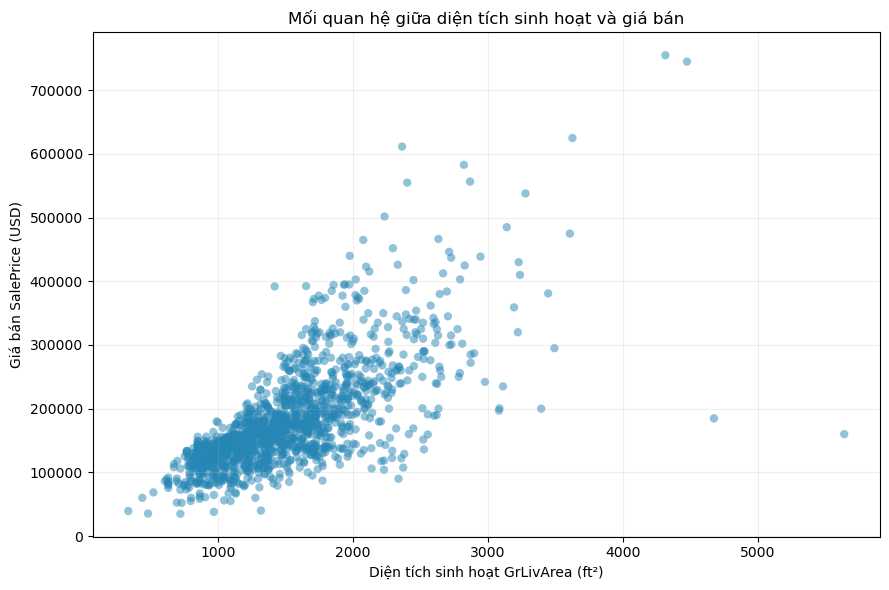

In [7]:
# Biểu đồ phân tán giữa diện tích sinh hoạt và giá bán
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    train["GrLivArea"],
    train["SalePrice"],
    alpha=0.5,
    color="#2686b5",
    edgecolors="none"
)

ax.set(
    title="Mối quan hệ giữa diện tích sinh hoạt và giá bán",
    xlabel="Diện tích sinh hoạt GrLivArea (ft²)",
    ylabel="Giá bán SalePrice (USD)"
)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


#### Nhận xét biểu đồ 7.1 – Diện tích sinh hoạt và giá bán

- Giá bán nhìn chung có xu hướng tăng khi diện tích sinh hoạt trên mặt đất (`GrLivArea`) tăng. Điều này phù hợp với hệ số tương quan Pearson **0,709** đã tính ở mục 6.
- Các điểm dữ liệu vẫn phân tán quanh xu hướng chung: những căn có diện tích tương tự có thể có giá khác nhau, cho thấy giá còn liên quan đến nhiều đặc trưng khác.
- Có hai căn diện tích rất lớn nhưng giá tương đối thấp kiểm tra hai căn bên dưới

In [8]:
# Kiểm chứng các điểm diện tích lớn quan sát được trên scatter plot.
large_houses = train.loc[
    train["GrLivArea"] > 4000,
    [
        "Id", "GrLivArea", "SalePrice", "OverallQual",
        "Neighborhood", "YearBuilt", "SaleType", "SaleCondition"
    ]
].sort_values("GrLivArea")

display(large_houses)

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,YearBuilt,SaleType,SaleCondition
691,692,4316,755000,10,NoRidge,1994,WD,Normal
1182,1183,4476,745000,10,NoRidge,1996,WD,Abnorml
523,524,4676,184750,10,Edwards,2007,New,Partial
1298,1299,5642,160000,10,Edwards,2008,New,Partial


### Nhận xét 
- Vậy hai căn diện tích rất lớn nhưng giá tương đối thấp: căn có `Id` **524** rộng 4.676 ft², giá 184.750 USD và căn có `Id` **1299** rộng 5.642 ft², giá 160.000 USD. Đây là những điểm cần kiểm tra thêm, chưa đủ cơ sở để kết luận là dữ liệu lỗi hoặc loại bỏ

### Biểu đồ 7.2. Giá bán theo chất lượng tổng thể

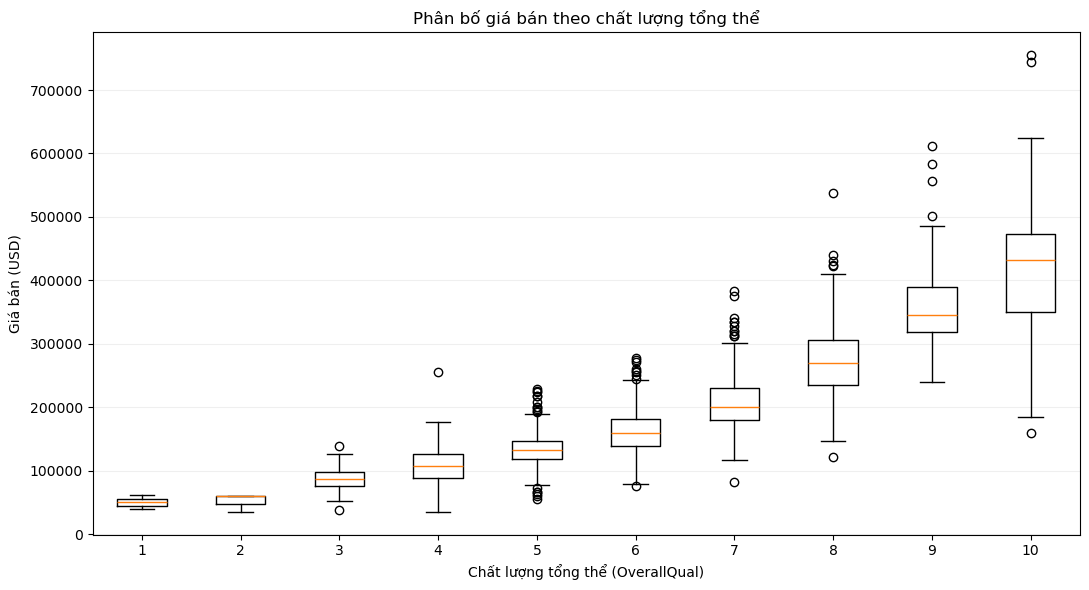

,so_luong_nha,gia_trung_vi
OverallQual,,
1,2,50150.0
2,3,60000.0
3,20,86250.0
4,116,108000.0
5,397,133000.0
6,374,160000.0
7,319,200141.0
8,168,269750.0
9,43,345000.0


In [9]:
# Phân bố giá bán theo từng mức chất lượng tổng thể
quality_levels = sorted(train["OverallQual"].dropna().unique())

price_by_quality = [
    train.loc[train["OverallQual"] == level, "SalePrice"].dropna()
    for level in quality_levels
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.boxplot(price_by_quality, tick_labels=quality_levels)

ax.set(
    title="Phân bố giá bán theo chất lượng tổng thể",
    xlabel="Chất lượng tổng thể (OverallQual)",
    ylabel="Giá bán (USD)"
)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# Số lượng nhà và giá trung vị ở từng mức chất lượng
quality_summary = (
    train.groupby("OverallQual")["SalePrice"]
    .agg(so_luong_nha="count", gia_trung_vi="median")
    .sort_index()
)

display(quality_summary)

### Nhận xét biểu đồ 7.2 – Giá bán theo chất lượng tổng thể

- Giá bán trung vị tăng theo từng mức `OverallQual`: từ **50.150 USD** ở mức 1 lên **432.390 USD** ở mức 10. Điều này cho thấy nhà có chất lượng tổng thể cao hơn thường có giá bán cao hơn.
- Các mức chất lượng 5, 6 và 7 có nhiều quan sát nhất, lần lượt là **397, 374 và 319 căn**. Giá trung vị tương ứng là **133.000, 160.000 và 200.141 USD**.
- Mức 1 chỉ có **2 căn** và mức 2 có **3 căn**; vì vậy, cần thận trọng khi nhận xét về hai nhóm này.
- Giá trong từng mức chất lượng vẫn có độ phân tán, nên `OverallQual` không phải là yếu tố duy nhất liên quan đến giá nhà.

## 8. Kiểm tra hai căn diện tích lớn trong bối cảnh khu vực và chất lượng


SaleType: Type of sale
		
       WD 	Warranty Deed - Conventional
       CWD	Warranty Deed - Cash
       VWD	Warranty Deed - VA Loan
       New	Home just constructed and sold
       COD	Court Officer Deed/Estate
       Con	Contract 15% Down payment regular terms
       ConLw	Contract Low Down payment and low interest
       ConLI	Contract Low Interest
       ConLD	Contract Low Down
       Oth	Other 

SaleCondition: Condition of sale

       Normal	Normal Sale
       Abnorml	Abnormal Sale -  trade, foreclosure, short sale
       AdjLand	Adjoining Land Purchase
       Alloca	Allocation - two linked properties with separate deeds, typically condo with a garage unit	
       Family	Sale between family members
       Partial	Home was not completed when last assessed (associated with New Homes) 

Số căn tại Edwards, chất lượng 8–10: 3


,OverallQual,SaleCondition,so_can,gia_trung_vi
0,9,Normal,1,320000.0
1,10,Partial,2,172375.0


,Id,GrLivArea,SalePrice,OverallQual,YearBuilt,SaleType,SaleCondition
724,725,1698,320000,9,2007,WD,Normal
523,524,4676,184750,10,2007,New,Partial
1298,1299,5642,160000,10,2008,New,Partial


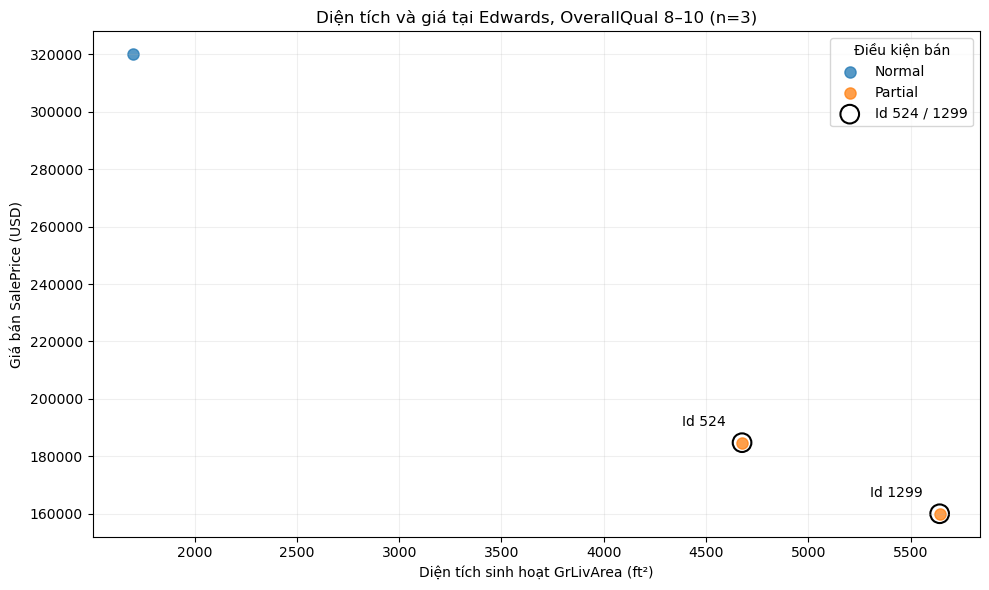

In [10]:
# Đối chiếu mã giao dịch với mô tả gốc.
import re
import matplotlib.pyplot as plt

description = (DATA_DIR / "data_description.txt").read_text()
for section in re.split(r"\n(?=[A-Za-z0-9]+:)", description):
    if section.split(":", 1)[0].strip() in ["SaleType", "SaleCondition"]:
        print(section.strip(), "\n")

comparison = train.loc[
    train["Neighborhood"].eq("Edwards")
    & train["OverallQual"].between(8, 10)
].copy()
print("Số căn tại Edwards, chất lượng 8–10:", len(comparison))
display(comparison.groupby(["OverallQual", "SaleCondition"], dropna=False)
        .agg(so_can=("Id", "size"), gia_trung_vi=("SalePrice", "median"))
        .reset_index())
display(comparison[["Id", "GrLivArea", "SalePrice", "OverallQual",
                    "YearBuilt", "SaleType", "SaleCondition"]]
        .sort_values("GrLivArea"))

# Một scatter plot, đánh dấu hai căn đang kiểm tra; không xóa dữ liệu.
fig, ax = plt.subplots(figsize=(10, 6))
for condition, group in comparison.groupby("SaleCondition", dropna=False):
    ax.scatter(group["GrLivArea"], group["SalePrice"],
               label=str(condition), s=65, alpha=0.75)
flagged = comparison.loc[comparison["Id"].isin([524, 1299])]
ax.scatter(flagged["GrLivArea"], flagged["SalePrice"], s=180,
           facecolors="none", edgecolors="black", linewidths=1.5,
           label="Id 524 / 1299")
for _, row in flagged.iterrows():
    ax.annotate(f"Id {int(row['Id'])}",
                (row["GrLivArea"], row["SalePrice"]),
                xytext=(-12, 12), textcoords="offset points", ha="right")
ax.set(title=f"Diện tích và giá tại Edwards, OverallQual 8–10 (n={len(comparison)})",
       xlabel="Diện tích sinh hoạt GrLivArea (ft²)",
       ylabel="Giá bán SalePrice (USD)")
ax.legend(title="Điều kiện bán")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


Nhận xét
- Nhóm Edwards có chất lượng tổng thể 8–10 gồm 3 căn. Hai căn Id 524 và 1299 có diện tích lớn nhưng giá lần lượt chỉ 184.750 USD và 160.000 USD, thấp hơn căn Id 725 (320.000 USD).
- Hai căn này cùng có SaleType = New và SaleCondition = Partial. Theo mô tả dữ liệu, Partial biểu thị nhà chưa hoàn thiện tại lần đánh giá gần nhất, không nhất thiết tại thời điểm bán.
- Nhóm so sánh quá nhỏ và các căn khác nhau về nhiều đặc điểm, nên chưa đủ bằng chứng giải thích nguyên nhân chênh lệch giá. Giữ nguyên hai căn, chưa loại bỏ vì chưa xác định được lỗi dữ liệu.

## 9. Phân bố giá bán theo khu vực


,so_can,gia_trung_vi
Neighborhood,,
MeadowV,17,88000.0
IDOTRR,37,103000.0
BrDale,16,106000.0
OldTown,113,119000.0
Edwards,100,121750.0
BrkSide,58,124300.0
Sawyer,74,135000.0
Blueste,2,137500.0
SWISU,25,139500.0


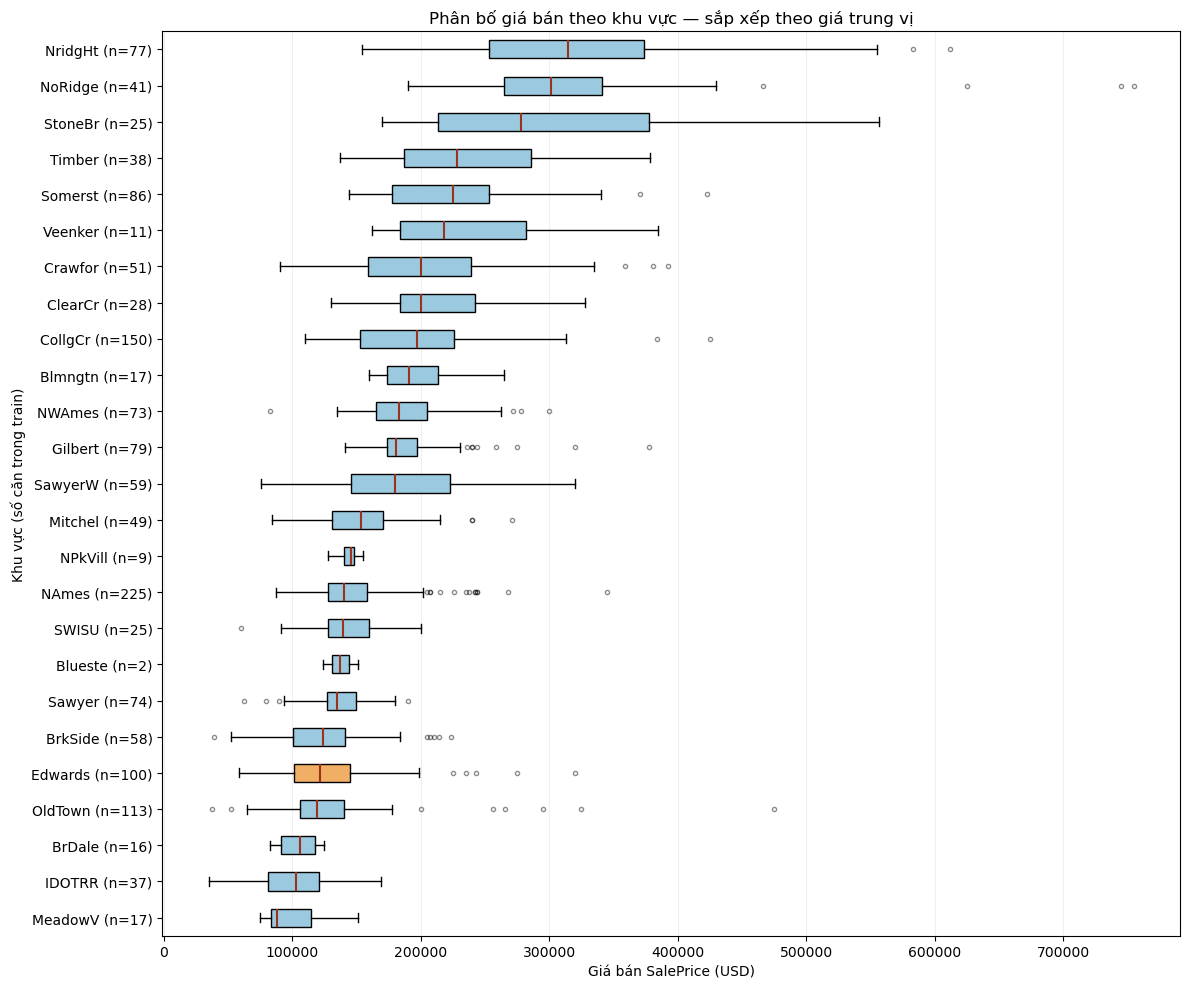

In [11]:
import matplotlib.pyplot as plt

# Thống kê và sắp xếp khu vực theo giá trung vị.
neighborhood_summary = (
    train.groupby("Neighborhood")["SalePrice"]
    .agg(so_can="count", gia_trung_vi="median")
    .sort_values("gia_trung_vi")
)
display(neighborhood_summary)

order = neighborhood_summary.index.tolist()
prices = [train.loc[train["Neighborhood"].eq(name), "SalePrice"].dropna()
          for name in order]
labels = [f"{name} (n={int(neighborhood_summary.loc[name, 'so_can'])})"
          for name in order]

# Một boxplot ngang; tô nổi bật Edwards để đối chiếu mục 8.
fig, ax = plt.subplots(figsize=(12, 10))
boxes = ax.boxplot(
    prices, vert=False, tick_labels=labels, patch_artist=True,
    medianprops={"color": "#9c321c", "linewidth": 1.5},
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.45}
)
for patch, name in zip(boxes["boxes"], order):
    patch.set_facecolor("#f1ae65" if name == "Edwards" else "#9bc9df")
ax.set(title="Phân bố giá bán theo khu vực — sắp xếp theo giá trung vị",
       xlabel="Giá bán SalePrice (USD)", ylabel="Khu vực (số căn trong train)")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


### Nhận xét biểu đồ mục 9 – Phân bố giá bán theo khu vực

- Giá bán trung vị có sự khác biệt giữa các khu vực. Trong tập train, `NridgHt` có trung vị cao nhất, **315.000 USD** với 77 căn; tiếp theo là `NoRidge`, **301.500 USD** với 41 căn.
- `MeadowV` có giá trung vị thấp nhất, **88.000 USD** với 17 căn. Khu vực `Edwards`, được khảo sát ở mục 8, có trung vị **121.750 USD** với 100 căn.
- Số lượng quan sát giữa các khu vực không đồng đều. Ví dụ, `Blueste` chỉ có 2 căn, nên cần thận trọng khi so sánh trung vị của khu vực này với các khu vực có nhiều dữ liệu hơn.
- Biểu đồ cho thấy khu vực có thể là đặc trưng hữu ích để thử trong mô hình dự đoán. Tuy nhiên, nhà ở các khu vực có thể khác nhau về diện tích, chất lượng và nhiều yếu tố khác; chưa thể kết luận chênh lệch giá chỉ do khu vực.

## 10. Kiểm tra tương quan giữa các đặc trưng số


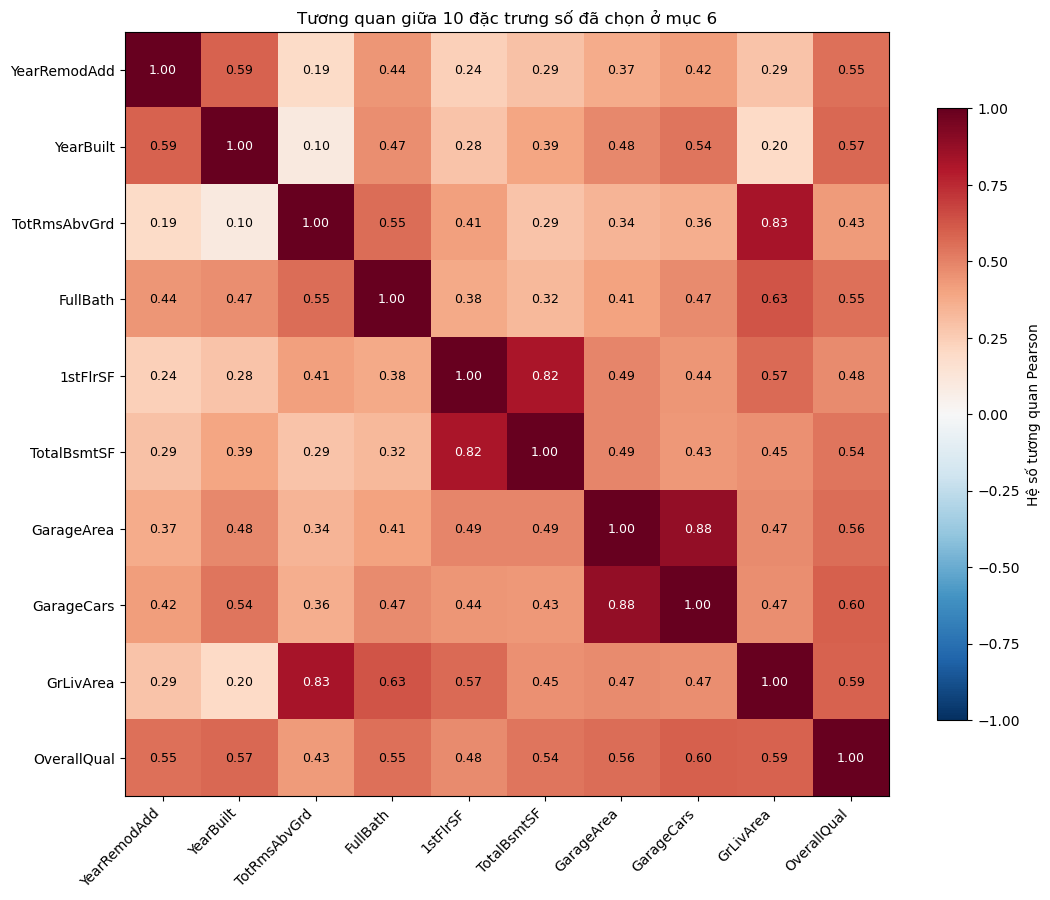

,feature_1,feature_2,pearson_r,abs_r
39,GarageArea,GarageCars,0.882,0.882
22,TotRmsAbvGrd,GrLivArea,0.825,0.825
30,1stFlrSF,TotalBsmtSF,0.820,0.820
28,FullBath,GrLivArea,0.630,0.630
43,GarageCars,OverallQual,0.601,0.601
44,GrLivArea,OverallQual,0.593,0.593
0,YearRemodAdd,YearBuilt,0.593,0.593
16,YearBuilt,OverallQual,0.572,0.572
33,1stFlrSF,GrLivArea,0.566,0.566
41,GarageArea,OverallQual,0.562,0.562


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Dùng đúng 10 đặc trưng đã chọn ở mục 6, không đưa SalePrice vào.
selected_features = top_correlations.index.tolist()
feature_correlations = train[selected_features].corr(method="pearson")

# Một heatmap; Pearson được tính trên các cặp giá trị không thiếu.
fig, ax = plt.subplots(figsize=(11, 9))
heatmap = ax.imshow(feature_correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(selected_features)), labels=selected_features,
              rotation=45, ha="right")
ax.set_yticks(range(len(selected_features)), labels=selected_features)
for row in range(len(selected_features)):
    for col in range(len(selected_features)):
        value = feature_correlations.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.65 else "black", fontsize=9)
fig.colorbar(heatmap, ax=ax, label="Hệ số tương quan Pearson", shrink=0.8)
ax.set_title("Tương quan giữa 10 đặc trưng số đã chọn ở mục 6")
fig.tight_layout()
plt.show()

# Bảng đối chiếu: chỉ lấy một lần mỗi cặp và bỏ đường chéo.
upper_triangle = np.triu(np.ones(feature_correlations.shape, dtype=bool), k=1)
feature_pairs = (
    feature_correlations.where(upper_triangle)
    .stack()
    .rename("pearson_r")
    .rename_axis(["feature_1", "feature_2"])
    .reset_index()
)
feature_pairs["abs_r"] = feature_pairs["pearson_r"].abs()
display(feature_pairs.sort_values("abs_r", ascending=False).head(10).round(3))


### Nhận xét

- Theo bảng feature_pairs, ba cặp có tương quan Pearson mạnh nhất là GarageArea–GarageCars (0,882), TotRmsAbvGrd–GrLivArea (0,825) và 1stFlrSF–TotalBsmtSF (0,820).
- Các cặp trên có thể mang thông tin chồng lấn, cần `lưu ý khi xây dựng mô hình tuyến tính`. Tuy nhiên, tương quan cao chưa đủ để quyết định loại biến; hiện giữ nguyên và đánh giá lựa chọn bằng cross-validation khi huấn luyện.
- Kết quả chỉ áp dụng cho 10 đặc trưng đã chọn ở mục 6, không bao quát toàn bộ dữ liệu.

## 11. Tổng kết khám phá dữ liệu

- **Giá bán:** `SalePrice` lệch phải. Sau biến đổi `log1p`, phân phối cân đối hơn; đây là một phương án để thử khi huấn luyện mô hình.
- **Giá trị thiếu:** Một số mã `NA` biểu thị căn nhà không có tiện ích, trong khi những giá trị khác có thể là thông tin chưa biết. Cần đối chiếu ý nghĩa từng cột và phân biệt `None` với `NA` ở `MasVnrType` khi tiền xử lý.
- **Đặc trưng nổi bật:** `OverallQual` và `GrLivArea` có tương quan Pearson cao với giá bán. Phân tích khu vực cũng cho thấy `Neighborhood` có thể hữu ích cho việc dự đoán.
- **Điểm cần lưu ý:** Hai căn `Id` 524 và 1299 có diện tích rất lớn nhưng giá tương đối thấp. Chưa đủ bằng chứng xác định đây là lỗi dữ liệu, nên hiện giữ nguyên và tiếp tục đánh giá ảnh hưởng khi xây dựng mô hình.
- **Tương quan giữa các đặc trưng:** Một số cặp có tương quan cao, như `GarageArea`–`GarageCars` và `TotRmsAbvGrd`–`GrLivArea`. Chưa loại biến chỉ dựa vào tương quan; cần so sánh các phương án khi đánh giá mô hình.

Những kết quả này là cơ sở để thiết kế tiền xử lý và xây dựng mô hình baseline. Các kết luận về khả năng dự đoán cần được kiểm chứng bằng phương pháp đánh giá phù hợp.